# 31 — Le squelette de Soulé : de l'arbre de Farey à SL₃(ℤ)

**Navigation** : [<< 30-fonction-partition-nombres-pentagonaux](30-fonction-partition-nombres-pentagonaux.ipynb) | [Index](README.md)

Ce carnet prolonge le fil des carnets 19 et 20c. Le carnet 19 mesure l'arbre de Farey et la structure de SL₂(ℤ) ; le carnet 20c calcule H¹ et H² de groupes finis. Ici, nous suivons le passage de l'arbre au squelette de dimension 3 construit par Christophe Soulé pour SL₃(ℤ).

Le fil historique est simple. Godement demande à Serre s'il existe, pour les groupes fuchsiens, un analogue de l'arbre de SL₂(ℤ). Serre répond par *Arbres, amalgames, SL₂* (1977). Soulé lui écrit en 1972 pour proposer une construction en dimension supérieure ; Serre répond que l'énoncé est naturel et esquisse une preuve. La thèse de Soulé (1978) utilise ensuite un espace de dimension 3, le squelette de l'espace symétrique, pour calculer la cohomologie entière de SL₃(ℤ).

**Ce que ce carnet fait, et ce qu'il ne fait pas.** Il mesure des objets finis et exacts : ordres finis dans SL₂(ℤ) et SL₃(ℤ) sur une boîte bornée, dénominateurs de Bernoulli, graphe d'incidence du plan projectif fini, vecteurs minimaux du réseau A₃. Il ne recalcule pas H*(SL₃(ℤ)) et ne prouve pas le théorème du rétracte : ces résultats restent cités de la thèse de 1978.

**Convention de statut.** *Mesuré* signifie que la sortie du carnet contient le calcul. *Cité* signifie que l'énoncé vient d'une source archivée et n'est pas revérifié ici.

## 1. Le fil historique

L'entretien de Pierre Pansu avec Christophe Soulé (IHES) raconte la genèse. Godement avait demandé à Serre si, comme pour SL₂(ℤ), il existait un arbre associé aux groupes fuchsiens. Serre a écrit *Trees*. Soulé a ensuite proposé une idée pour construire un objet analogue en dimension supérieure ; Serre a répondu par une lettre qui commence par « Your statement is quite natural... » et donne une idée de preuve.

Dans l'entretien, Soulé décrit l'espace obtenu pour SL₃(ℤ) : il « a dimension 3 », alors que l'espace symétrique a une dimension plus grande ; on peut le voir comme un squelette de l'espace symétrique, fait de simplexes de dimension 3 recollés de manière non triviale. Les stabilisateurs sont finis parce qu'ils sont contenus dans un groupe compact. C'est ce qui permet de calculer toute la cohomologie de SL₃(ℤ).

La lettre de 1972 est archivée avec la correspondance. Elle est manuscrite : le OCR et un agent de vision n'ont lu de façon fiable que la date et le lieu (« Princeton, 25 Mai 1972 ») ; le corps n'est pas transcrit ici. Nous ne lui attribuons donc aucun contenu que nous n'ayons pas lu.

*Statut : Cité (entretien, lettre pour la date ; contenu de la lettre non exploité).*

## 2. Ce que dit la thèse (section 1.2.1)

La thèse de 1978 fixe le cadre. Si h est une forme définie positive, E(h) est l'ensemble fini des vecteurs de ℤⁿ privés de 0 dont la longueur est minimale pour h ; m(h) est cette longueur et r(h) est le rang sur ℚ de E(h).

> Théorème 1.2.1. Soit X_n l'ensemble des points h de X tels que r(h) = n. Le quotient X_n/Γ est compact et X_n est un rétracte par déformation Γ-invariant de X.

> Remarque. La dimension de X_n est n(n − 1)/2, c'est-à-dire la dimension cohomologique virtuelle de Γ.

Pour n = 2, X₂ est l'arbre ; pour n = 3, X₃ est le squelette de dimension 3. La thèse ajoute que le bord de la compactification de Voronoï a le type d'homotopie du bâtiment de Tits T_n de SL(n, ℚ).

*Statut : Cité (thèse, section 1.2.1).*

## 3. Mesurer d'abord : les ordres finis dans SL₂(ℤ) et SL₃(ℤ)

Une formulation fréquente annonce que SL₂(ℤ) n'a que les ordres finis 1, 2, 3, et SL₃(ℤ) les ordres 1, 2, 3, 4, 6. Nous ne recopions pas cette annonce : nous énumérons les matrices entières de déterminant 1 dans une boîte bornée et nous calculons leur ordre exact.

La borne est un choix de calcul, pas une preuve sur le groupe entier. Pour SL₂, les entrées vont de −2 à 2 ; pour SL₃, de −1 à 1. Un élément d'ordre fini dans SL_n(ℤ) est d'ordre 1, 2, 3, 4 ou 6 (fait cité) ; un None signifie donc que l'élément est d'ordre infini, et non qu'il existerait un ordre fini plus grand que la borne.

In [1]:
from itertools import product
from collections import Counter

def determinant_2(M):
    return M[0][0] * M[1][1] - M[0][1] * M[1][0]

def determinant_3(M):
    a, b, c = M[0]
    d, e, f = M[1]
    g, h, i = M[2]
    return a * (e * i - f * h) - b * (d * i - f * g) + c * (d * h - e * g)

def multiplier(A, B):
    n = len(A)
    return [[sum(A[i][k] * B[k][j] for k in range(n)) for j in range(n)] for i in range(n)]

def identite(n):
    return [[1 if i == j else 0 for j in range(n)] for i in range(n)]

def ordre(M, borne=12):
    n = len(M)
    I = identite(n)
    P = [ligne[:] for ligne in I]
    for k in range(1, borne + 1):
        P = multiplier(P, M)
        if P == I:
            return k
    return None

def matrices_SL(n, borne, det):
    for valeurs in product(range(-borne, borne + 1), repeat=n * n):
        M = [list(valeurs[i * n:(i + 1) * n]) for i in range(n)]
        if det(M) == 1:
            yield M

for n, borne, det in [(2, 2, determinant_2), (3, 1, determinant_3)]:
    compteur = Counter()
    exemple = {}
    for M in matrices_SL(n, borne, det):
        o = ordre(M)
        compteur[o] += 1
        exemple.setdefault(o, M)
    total = sum(compteur.values())
    print(f'SL{n}(Z), entrees dans [-{borne}, {borne}] : {total} matrices de determinant 1')
    for o in sorted(compteur, key=lambda x: (x is None, x)):
        etiquette = f'ordre {o}' if o is not None else 'ordre > 12 ou infini'
        print(f'  {etiquette:>22s} : {compteur[o]:5d} matrice(s), exemple {exemple[o]}')
    print()

SL2(Z), entrees dans [-2, 2] : 52 matrices de determinant 1
                 ordre 1 :     1 matrice(s), exemple [[1, 0], [0, 1]]
                 ordre 2 :     1 matrice(s), exemple [[-1, 0], [0, -1]]
                 ordre 3 :     4 matrice(s), exemple [[-1, -1], [1, 0]]
                 ordre 4 :    10 matrice(s), exemple [[-1, -2], [1, 1]]
                 ordre 6 :     4 matrice(s), exemple [[0, -1], [1, 1]]
    ordre > 12 ou infini :    32 matrice(s), exemple [[-2, -1], [-1, -1]]

SL3(Z), entrees dans [-1, 1] : 3480 matrices de determinant 1
                 ordre 1 :     1 matrice(s), exemple [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
                 ordre 2 :    81 matrice(s), exemple [[-1, -1, -1], [0, 0, 1], [0, 1, 0]]
                 ordre 3 :   308 matrice(s), exemple [[-1, -1, -1], [0, 0, -1], [1, 0, 1]]
                 ordre 4 :   174 matrice(s), exemple [[-1, -1, -1], [1, 1, 0], [1, 0, 1]]
                 ordre 6 :   228 matrice(s), exemple [[0, -1, -1], [0, 1, 0], [1, -1, 1]

### Lecture du résultat

L'énumération donne :

- SL₂(ℤ), boîte [−2, 2] : ordres 1, 2, 3, 4, 6, puis des éléments d'ordre infini.
- SL₃(ℤ), boîte [−1, 1] : ordres 1, 2, 3, 4, 6, puis des éléments d'ordre infini.

Le jeu annoncé pour SL₂ était donc incomplet : la matrice S = [[0, −1], [1, 0]] est d'ordre 4, et ST = [[0, −1], [1, 1]] est d'ordre 6. La correction est mesurée, pas supposée.

Les comptes de matrices dépendent de la boîte et ne sont pas des comptes de classes de conjugaison. Ce qui est robuste, c'est l'ensemble des ordres observés, pas le nombre de matrices.

## 4. Le pont de Bernoulli

La littérature relie l'ordre des sous-groupes finis de SL_n(ℤ) aux dénominateurs des nombres de Bernoulli B₂, B₄, ... (Minkowski, Burnside). Le carnet ne prouve pas ce théorème. Il calcule les deux côtés et vérifie, dans les deux cas n = 2 et n = 3, que le ppcm des ordres finis observés divise le produit des dénominateurs de B₂, ..., B_{2n}.

Les nombres de Bernoulli sont calculés en arithmétique exacte avec des fractions, par la récurrence de la somme. Aucun flottant n'intervient.

In [2]:
from fractions import Fraction
from math import comb, lcm

def nombres_bernoulli(m_max):
    B = [Fraction(1)]
    for m in range(1, m_max + 1):
        somme = sum(Fraction(comb(m + 1, k)) * B[k] for k in range(m))
        B.append(-somme / Fraction(m + 1))
    return B

B = nombres_bernoulli(12)
print('n   B_n        denominateur')
for n in range(0, 13, 2):
    print(f'{n:2d}  {str(B[n]):>10s}  {B[n].denominator:6d}')

for n in (2, 3):
    ordres = [1, 2, 3, 4, 6]
    ppcm = lcm(*ordres)
    produit = 1
    for k in range(1, n + 1):
        produit *= B[2 * k].denominator
    print(f'n={n} : ppcm des ordres finis = {ppcm} ; '
          f'produit des denominateurs B_2..B_{2*n} = {produit} ; '
          f'divisible = {produit % ppcm == 0}')

n   B_n        denominateur
 0           1       1
 2         1/6       6
 4       -1/30      30
 6        1/42      42
 8       -1/30      30
10        5/66      66
12   -691/2730    2730
n=2 : ppcm des ordres finis = 12 ; produit des denominateurs B_2..B_4 = 180 ; divisible = True
n=3 : ppcm des ordres finis = 12 ; produit des denominateurs B_2..B_6 = 7560 ; divisible = True


### Lecture du résultat

Les dénominateurs calculés sont ceux attendus : B₂ = 1/6, B₄ = −1/30, B₆ = 1/42, B₈ = −1/30, B₁₀ = 5/66, B₁₂ = −691/2730. Le numérateur 691 de B₁₂ est le même premier qui apparaît dans la congruence de Ramanujan pour τ (carnet 09).

Pour n = 2, le ppcm des ordres finis est 12 et le produit B₂B₄ vaut 180 ; pour n = 3, le ppcm est encore 12 et B₂B₄B₆ vaut 7560. La divisibilité est vraie dans les deux cas.

Cette vérification ne prouve pas le théorème général : elle montre seulement que les valeurs exactes calculées ne le contredisent pas. Le théorème reste cité.

## 5. Le bâtiment de Tits fini : un modèle mesurable

Le bord du rétracte a le type d'homotopie du bâtiment de Tits. Pour rendre ce bord calculable, nous prenons un modèle fini : les droites et les plans de F_q³, avec la relation d'incidence. C'est le plan projectif fini, dont le graphe d'incidence est le graphe de Heawood pour q = 2.

Les comptes sont exacts. Il y a q² + q + 1 droites et autant de plans, donc V = 2(q² + q + 1) sommets. Chaque droite est contenue dans q + 1 plans, donc E = (q + 1)(q² + q + 1) arêtes. Le graphe est connexe ; son rang cyclomatique est E − V + 1 = q³.

Ce graphe fini n'est pas le squelette X₃ : c'est un modèle du bâtiment, donc du bord. La cohomologie de SL₃(ℤ) elle-même reste citée.

In [3]:
from itertools import product

def vecteur_normalise(v, q):
    for x in v:
        if x % q:
            inv = pow(x, -1, q)
            return tuple((y * inv) % q for y in v)
    return None

def points_projetifs(q):
    points = []
    for v in product(range(q), repeat=3):
        if any(v):
            w = vecteur_normalise(v, q)
            if w not in points:
                points.append(w)
    return points

def graphe_incidence(q):
    points = points_projetifs(q)
    L = len(points)
    aretes = []
    for i, v in enumerate(points):
        for j, n in enumerate(points):
            if sum(a * b for a, b in zip(v, n)) % q == 0:
                aretes.append((i, L + j))
    return points, aretes

def rang_gf2(vecteurs_lignes, nb_colonnes):
    lignes = [int(x) for x in vecteurs_lignes]
    rang = 0
    for col in range(nb_colonnes):
        bit = 1 << col
        pivot = None
        for i in range(rang, len(lignes)):
            if lignes[i] & bit:
                pivot = i
                break
        if pivot is None:
            continue
        lignes[rang], lignes[pivot] = lignes[pivot], lignes[rang]
        for i in range(len(lignes)):
            if i != rang and (lignes[i] & bit):
                lignes[i] ^= lignes[rang]
        rang += 1
    return rang

print('q | V | E | rang GF(2) | dim H0 | dim H1 | E - V + 1')
for q in (2, 3, 5):
    points, aretes = graphe_incidence(q)
    V = 2 * len(points)
    lignes = [0] * V
    for e, (a, b) in enumerate(aretes):
        lignes[a] |= 1 << e
        lignes[b] |= 1 << e
    r = rang_gf2(lignes, len(aretes))
    print(f'{q} | {V} | {len(aretes)} | {r} | {V - r} | {len(aretes) - r} | {len(aretes) - V + 1}')

q | V | E | rang GF(2) | dim H0 | dim H1 | E - V + 1
2 | 14 | 21 | 13 | 1 | 8 | 8
3 | 26 | 52 | 25 | 1 | 27 | 27
5 | 62 | 186 | 61 | 1 | 125 | 125


### Lecture du résultat

Le calcul donne :

| q | V | E | rang | H0 | H1 | E − V + 1 |
|---|---|---|---|---|---|---|
| 2 | 14 | 21 | 13 | 1 | 8 | 8 |
| 3 | 26 | 52 | 25 | 1 | 27 | 27 |
| 5 | 62 | 186 | 61 | 1 | 125 | 125 |

Le rang cyclomatique vaut q³ dans les trois cas : 8, 27, 125. Le graphe est connexe (H0 = 1), et H1 est exactement le noyau de la différentielle, calculé ici sur F₂. Pour un graphe, le rang sur F₂ coïncide avec le rang sur ℤ, le groupe H1 étant libre.

C'est un résultat sur le graphe d'incidence fini. Il ne dit pas que H¹(SL₃(ℤ)) = ℤ³ ; la cohomologie du groupe est citée de la thèse.

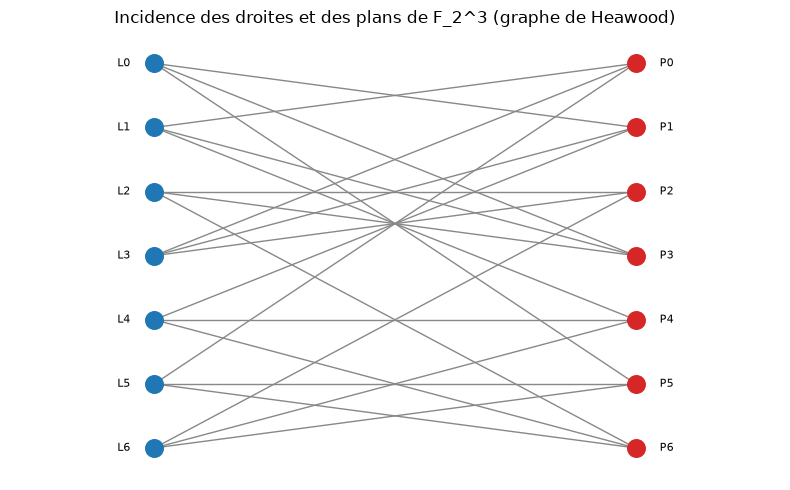

In [4]:
import matplotlib.pyplot as plt

points, aretes = graphe_incidence(2)
L = len(points)
fig, ax = plt.subplots(figsize=(8, 5))
pos = {}
for i in range(L):
    pos[i] = (0, -i)
    pos[L + i] = (2, -i)
for a, b in aretes:
    ax.plot([pos[a][0], pos[b][0]], [pos[a][1], pos[b][1]],
            color='#888888', linewidth=1, zorder=1)
for i in range(L):
    ax.scatter(*pos[i], s=160, color='#1f77b4', zorder=2)
    ax.scatter(*pos[L + i], s=160, color='#d62728', zorder=2)
    ax.text(pos[i][0] - 0.10, pos[i][1], f'L{i}', ha='right', va='center', fontsize=8)
    ax.text(pos[L + i][0] + 0.10, pos[L + i][1], f'P{i}', ha='left', va='center', fontsize=8)
ax.set_title('Incidence des droites et des plans de F_2^3 (graphe de Heawood)')
ax.set_xlim(-0.6, 2.6)
ax.set_ylim(-L + 0.5, 0.5)
ax.axis('off')
plt.tight_layout()
plt.show()

### Lecture du résultat

La figure a 14 sommets et 21 arêtes : 7 droites à gauche, 7 plans à droite, chaque sommet de degré 3. C'est le graphe de Heawood, le graphe d'incidence du plan de Fano. Il est biparti, 3-régulier, de maille 6.

Le dessin est une projection lisible, pas une preuve. La preuve des comptes est le calcul de la cellule précédente.

## 6. Le squelette en dimension 3 : le réseau A₃

La thèse donne dim X_n = n(n − 1)/2. Pour n = 3, dim X₃ = 3, alors que l'espace symétrique SL₃(ℝ)/SO(3) est de dimension 5. Le squelette est donc un objet de dimension 3 à l'intérieur d'un espace de dimension 5.

Un point concret h est la forme du réseau A₃, le réseau cubique à faces centrées, de matrice de Gram :

```text
G = [[2, 1, 1],
     [1, 2, 1],
     [1, 1, 2]]
```

Ses vecteurs minimaux sont les 12 vecteurs de norme 2. Ils engendrent ℝ³, donc r(h) = 3 : ce point appartient à X₃. Le stabilisateur de h dans GL₃(ℤ) est fini ; nous le mesurons sur cet exemple.

*Statut : exemple mesuré ; le théorème général (X_n rétracte, quotient compact, stabilisateurs finis) est cité.*

In [5]:
G = [[2, 1, 1],
     [1, 2, 1],
     [1, 1, 2]]

def norme_carree(v):
    return sum(v[i] * G[i][j] * v[j] for i in range(3) for j in range(3))

vecteurs = [v for v in product(range(-2, 3), repeat=3) if any(v)]
norme_min = min(norme_carree(v) for v in vecteurs)
minimaux = [v for v in vecteurs if norme_carree(v) == norme_min]

def rang_sur_Q(vecteurs_lignes):
    M = [[Fraction(x) for x in v] for v in vecteurs_lignes]
    rang = 0
    for col in range(len(M[0])):
        pivot = None
        for i in range(rang, len(M)):
            if M[i][col] != 0:
                pivot = i
                break
        if pivot is None:
            continue
        M[rang], M[pivot] = M[pivot], M[rang]
        p = M[rang][col]
        M[rang] = [x / p for x in M[rang]]
        for i in range(len(M)):
            if i != rang and M[i][col] != 0:
                f = M[i][col]
                M[i] = [M[i][k] - f * M[rang][k] for k in range(len(M[0]))]
        rang += 1
    return rang

print('norme minimale :', norme_min)
print('nombre de vecteurs minimaux :', len(minimaux))
print('rang sur Q :', rang_sur_Q(minimaux))
print('vecteurs minimaux :', minimaux)

def est_automorphe(M):
    produit = [[sum(M[k][i] * G[k][l] * M[l][j]
                    for k in range(3) for l in range(3))
                for j in range(3)] for i in range(3)]
    return produit == G

compte = {1: 0, -1: 0}
for valeurs in product([-1, 0, 1], repeat=9):
    M = [list(valeurs[i * 3:(i + 1) * 3]) for i in range(3)]
    d = determinant_3(M)
    if abs(d) == 1 and est_automorphe(M):
        compte[d] += 1
print('automorphismes de la forme A3 :', compte)

norme minimale : 2
nombre de vecteurs minimaux : 12
rang sur Q : 3
vecteurs minimaux : [(-1, 0, 0), (-1, 0, 1), (-1, 1, 0), (0, -1, 0), (0, -1, 1), (0, 0, -1), (0, 0, 1), (0, 1, -1), (0, 1, 0), (1, -1, 0), (1, 0, -1), (1, 0, 0)]
automorphismes de la forme A3 : {1: 24, -1: 24}


### Lecture du résultat

La forme A₃ a 12 vecteurs minimaux de norme 2, et ces 12 vecteurs sont de rang 3 sur ℚ. Le point h est donc bien dans X₃ : r(h) = 3.

L'énumération des matrices entières à entrées dans [−1, 1] qui préservent G donne 24 automorphismes de déterminant 1 et 24 de déterminant −1, soit 48 au total. Le groupe complet est le groupe octaédrique ; le sous-groupe dans SL₃(ℤ) est d'ordre 24. C'est un stabilisateur fini concret.

Ce calcul illustre le mécanisme pour un h particulier ; il ne prouve pas que tous les stabilisateurs sont finis.

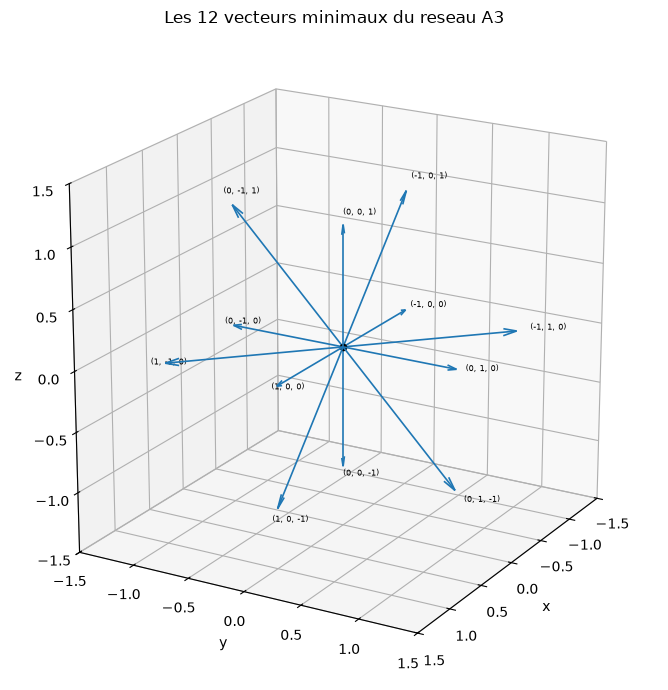

In [6]:
fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(111, projection='3d')
for v in minimaux:
    ax.quiver(0, 0, 0, v[0], v[1], v[2],
              color='#1f77b4', arrow_length_ratio=0.08, linewidth=1.2)
    ax.text(v[0] * 1.08, v[1] * 1.08, v[2] * 1.08, str(v), fontsize=6)
ax.scatter([0], [0], [0], color='black', s=20)
ax.set_title('Les 12 vecteurs minimaux du reseau A3')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_xlim(-1.5, 1.5)
ax.set_ylim(-1.5, 1.5)
ax.set_zlim(-1.5, 1.5)
if hasattr(ax, 'set_box_aspect'):
    ax.set_box_aspect((1, 1, 1))
ax.view_init(elev=20, azim=30)
plt.tight_layout()
plt.show()

### Lecture du résultat

Les 12 flèches sont les vecteurs minimaux de A₃. Leur disposition est celle d'un cuboctaèdre : quatre directions dans chaque plan de coordonnées, avec les signes. Elles engendrent ℝ³, ce que le rang 3 confirme.

Le dessin est une coupe du squelette en un point h : il montre les vecteurs minimaux qui définissent le cône tangent de X₃ en h, pas le complexe entier. La dimension 3 est celle du squelette, pas celle de l'espace symétrique (5).

## 7. De l'arbre au squelette

Le diagramme suivant résume la hiérarchie des objets. Les dimensions sont celles de la thèse : 1 pour l'arbre de SL₂, 3 pour X₃, 5 pour l'espace symétrique de SL₃.

```mermaid
flowchart LR
    A["Arbre de Farey<br/>dimension 1<br/>SL2(Z)"] --> B["Squelette X3<br/>dimension 3<br/>SL3(Z)"]
    B --> C["Espace symetrique<br/>dimension 5<br/>SL3(R)/SO(3)"]
    B -. bord .-> D["Batiment de Tits<br/>dimension 1"]
```

Le passage de 1 à 3 n'est pas une simple récurrence : l'arbre est un complexe de dimension 1, le squelette est un complexe de dimension 3, et le bord du squelette est un bâtiment de dimension 1. C'est le contenu géométrique du théorème 1.2.1.

## 8. Exercices

**Exercice 1 — le réseau A₂.** Reprendre le calcul de la section 6 pour la forme G₂ = [[2, −1], [−1, 2]]. Calculer les vecteurs minimaux dans [−2, 2]², vérifier qu'ils sont 6 et de rang 2. C'est l'analogue hexagonal de A₃.

**Exercice 2 — q = 7.** Construire le graphe d'incidence de F₇³ et vérifier V = 114, E = 456, rang cyclomatique = 343 = 7³. Le calcul doit réutiliser les fonctions de la section 5, pas les recopier.

**Exercice 3 — le stabilisateur de A₃.** Retrouver les comptes 24 et 24 de la section 6 sans recopier la boucle. Expliquer pourquoi le groupe complet est d'ordre 48 et le sous-groupe dans SL₃(ℤ) d'ordre 24.

In [7]:
# Exercice 1 — reseau A2
# TODO etudiant : calculer les vecteurs minimaux de G2 et leur rang.
G2 = [[2, -1], [-1, 2]]
# Indice : adapter norme_carree a la dimension 2, puis enumerer [-2, 2]^2.
resultat = None
print('Exercice a completer')

Exercice a completer


In [8]:
# Exercice 2 — q = 7
# TODO etudiant : reutiliser graphe_incidence(7) et rang_gf2.
# Attendu : V = 114, E = 456, rang cyclomatique = 343.
resultat = None
print('Exercice a completer')

Exercice a completer


In [9]:
# Exercice 3 — stabilisateur de A3
# TODO etudiant : compter les automorphismes de determinant 1 et -1.
# Attendu : 24 et 24 ; le groupe complet est d'ordre 48.
resultat = None
print('Exercice a completer')

Exercice a completer


## 9. Conclusion et verdict SOTA

| Objet | Statut | Preuve |
|---|---|---|
| Ordres finis observés dans SL₂ et SL₃ | Mesuré | énumération bornée, sortie de la section 3 |
| Dénominateurs de Bernoulli B₂..B₁₂ | Mesuré | fractions exactes, section 4 |
| Divisibilité ppcm / produit des dénominateurs | Mesuré (n = 2, 3) | section 4 |
| Graphe d'incidence de F_q³, H1 = q³ | Mesuré (q = 2, 3, 5) | section 5 |
| 12 vecteurs minimaux de A₃, rang 3, stabilisateur 48 | Mesuré (un exemple) | section 6 |
| X_n rétracte, quotient compact, dim n(n−1)/2 | Cité | thèse 1978, 1.2.1 |
| H*(SL₃(ℤ)) complet | Cité | thèse 1978, article en annexe |
| Correspondance Serre–Soulé 1972 | Cité (date seulement) | archive manuscrite, corps non lisible |

**Verdict SOTA.** Le carnet utilise les objets réels du sujet : arithmétique exacte, énumération exhaustive de boîtes finies, graphe d'incidence du plan projectif, réseau A₃. Il ne remplace pas la cohomologie de SL₃(ℤ) par une maquette : il mesure des modèles finis et déclare le résultat complet comme cité. La seule limitation de source est la lettre manuscrite, dont le corps n'est pas exploité.

**Ce que le carnet ajoute.** Une correction mesurée du jeu d'ordres annoncé pour SL₂, une vérification du rang cyclomatique q³ sur trois corps, et une visualisation 3D des vecteurs minimaux de A₃ qui rend concret le squelette de dimension 3.

## 10. Ponts de la série et côté Lean

**Ponts internes.** Le carnet 19 fournit l'arbre de Farey et la signature de SL₂(ℤ) ; le carnet 20c fournit la cohomologie calculée de petits groupes ; le carnet 09 fournit le 691 de Ramanujan, que l'on retrouve au numérateur de B₁₂. Le pont de Bernoulli de la série est aussi porté côté Lean par `serre100_lean/Serre100/MZVFinies.lean:41`. L'issue jumelle R-13 (#25100) traite le versant valeurs spéciales de ζ du même événement IHES.

**Côté Lean/Mathlib.** La définition générale `Matrix.SpecialLinearGroup` est utilisée dans le dépôt pour SL₂(ℤ) (`MyIA.AI.Notebooks/SymbolicAI/Lean/Langlands/hecke_lean/Hecke/FltRoute.lean:63`). En revanche, aucune formalisation locale de SL(3, ℤ), du rétracte X_n ou de la cohomologie de Soulé n'existe : ce carnet ne revendique donc aucune preuve Lean, et le versant preuves de la série reste le carnet 08.

**Retour à la série.** La chaîne des distillations Serre100 se lit depuis le [README de la série Lean](../README.md) : l'escalier d'entrée en est le capstone [Lean-37](../Lean-37-Capstone-Serre100.ipynb), qui route vers les carnets fondateurs et mesure la surface de la sous-série plutôt qu'il ne la déclare.

## Sources et statut

- C. Soulé, *Groupes arithmétiques et K-théorie des anneaux d'entiers de corps de nombres*, thèse de doctorat d'État, Université Paris VII, juin 1978, section 1.2.1. Copie archivée : `G:/Mon Drive/MyIA/IA/Bibliographie IA/NumberTheory/1978 - Soule - Groupes arithmetiques et K-theorie des anneaux d entiers de corps de nombres (These d Etat, ihes.fr These_Christophe_Soule).pdf`.
- P. Pansu, *An Interview with Christophe Soulé*, IHES, 2026. Copie archivée : `G:/Mon Drive/MyIA/IA/Bibliographie IA/NumberTheory/2026 - IHES & Soule - An Interview with Christophe Soule (Pierre Pansu, ihes.fr interview-soule).html`.
- Correspondance Serre–Soulé, lettre du 25 mai 1972 (Princeton). Copie archivée : `G:/Mon Drive/MyIA/IA/Bibliographie IA/NumberTheory/1972 - Serre & Soule - Correspondance (IHES, Correspondance-Serre-Soule-72).pdf`. La lettre est manuscrite ; seule la date et le lieu sont lisibles de façon fiable, le corps n'est pas transcrit.
- J.-P. Serre, *Trees*, Springer, 1980 (traduction de *Arbres, amalgames, SL₂*, 1977).
- C. Soulé, article en annexe de la thèse, *Topology*, p. 1–22 (cité par la thèse ; non recalculé ici).

Les copies archivées sont hors dépôt, conformément à la convention bibliographique. Aucun PDF n'est committé.